# Breast Cancer Classification 
This document summarizes the technical implementation of an Artificial Neural Network (ANN) used to classify breast cancer tumors (Malignant vs. Benign) using the Wisconsin Diagnostic Breast Cancer (WDBC) dataset.

## 1. Environment Setup & Data Ingestion
The notebook begins by importing the necessary libraries for data manipulation, machine learning, and deep learning:
*   **Data Manipulation & Visualization:** `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`
*   **Preprocessing & Metrics:** `train_test_split`, `StandardScaler`, `classification_report`, `confusion_matrix`, `roc_auc_score`, `roc_curve` (from `sklearn`)
*   **Deep Learning:** `Sequential`, `Input`, `Dense`, `Dropout`, `Adam` (from `tensorflow.keras`)
*   **Wrapper:** `KerasClassifier` (from `scikeras.wrappers`) for Scikit-Learn compatibility.

The dataset (`wdbc.data`) is loaded into a Pandas DataFrame with custom column names: `id`, `diagnosis`, and 30 continuous features (`feature_1` to `feature_30`).

## 2. Model Preparation & Hyperparameter Tuning
The data is scaled and split into training (455 samples) and testing (114 samples) sets. To find the optimal neural network configuration, `GridSearchCV` is utilized alongside Keras callbacks.

**Callbacks Configured:**
*   **EarlyStopping:** Monitors validation loss, stopping training if it doesn't improve for 10 epochs (restores best weights).
*   **ModelCheckpoint:** Saves the best model as `best_cancer_model.keras`.

**Grid Search Parameters:**
*   `learning_rate`: [0.001, 0.01]
*   `dropout_rate`: [0.2, 0.4]
*   `batch_size`: [16, 32]
*   `epochs`: [50]
*   *Cross-validation (cv):* 3 folds

**Grid Search Results:**
*   **Best Accuracy:** 0.9780
*   **Best Parameters:** `{'batch_size': 16, 'epochs': 50, 'model__dropout_rate': 0.2, 'model__learning_rate': 0.001}`

## 3. Model Evaluation
The best estimator from the grid search is evaluated against the unseen test data (114 samples).

**Performance Metrics:**
*   **Overall Accuracy:** 0.98 (98%)
*   **ROC-AUC Score:** 0.9957
*   **Classification Report:**
    *   *Benign (0):* Precision 0.97, Recall 1.00, F1-Score 0.99
    *   *Malignant (1):* Precision 1.00, Recall 0.95, F1-Score 0.98

**Visualizations Generated:**
1.  **Confusion Matrix (Heatmap):** Maps actual vs. predicted labels (Benign vs. Malignant) using `seaborn.heatmap` to visually identify false positives and false negatives.
2.  **ROC Curve:** Plots the True Positive Rate against the False Positive Rate using `matplotlib`, displaying an outstanding AUC of 0.9957.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasClassifier



column_names = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
cancer_data= pd.read_csv("Y:/Jupyter_Project/breast_cancer/wdbc.data",names=column_names)
cancer_data.head()

,id,diagnosis,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [21]:
df = cancer_data.drop('id', axis=1)
#Convert Diagnosis to Binary (Malignant = 1, Benign = 0)
df['diagnosis'] = df['diagnosis'].map({'M':1, 'B': 0})

df.head()

,diagnosis,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [22]:
#checking for missing values
print("Missing values in dataset:\n", df.isnull().sum().sum())


Missing values in dataset:
 0


C:\Users\Yatrik\AppData\Local\Temp\ipykernel_14220\619429048.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df, palette='Set2')


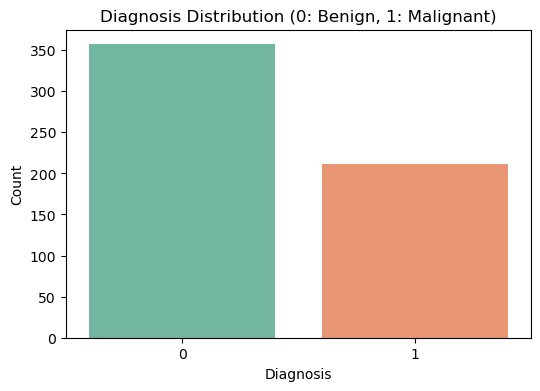

In [23]:
#Visualization
plt.figure(figsize=(6, 4))
sns.countplot(x='diagnosis', data=df, palette='Set2')
plt.title('Diagnosis Distribution (0: Benign, 1: Malignant)')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

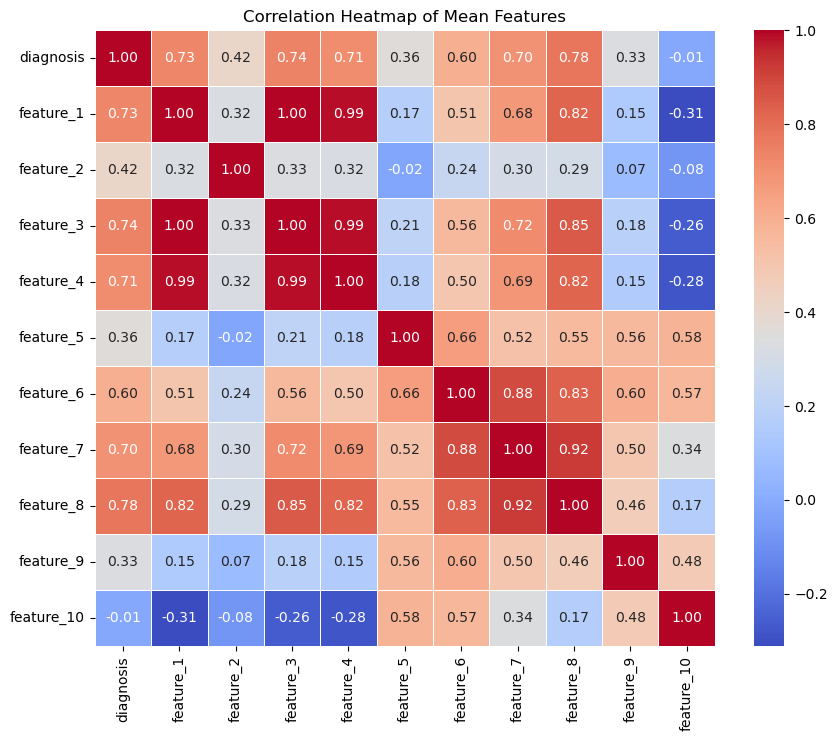

In [24]:
# Visualize feature correlations
# High correlation between features (like radius and area) means they provide redundant information
plt.figure(figsize=(10, 8))
mean_features = ['diagnosis'] + [f'feature_{i}' for i in range(1, 11)]
corr = df[mean_features].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Mean Features')
plt.show()

In [25]:
#Split Data into Features (X) and Target (y)
X = df.drop('diagnosis', axis=1)
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

#Train-Test Split (80% training, 20% validation/testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
# Neural Network Architecture with Dropout
def create_model(dropout_rate=0.2, learning_rate=0.001):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # <--- Add the dedicated Input layer here
        Dense(32, activation='relu'),            # <--- Remove input_shape from this Dense layer
        Dropout(dropout_rate),
        
        Dense(16, activation='relu'),
        Dropout(dropout_rate),
        
        Dense(1, activation='sigmoid')
    ])
    
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [27]:
#Keras model for Scikit-Learn compatibility

model_wrapper = KerasClassifier(model=create_model, verbose=0)

print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import GridSearchCV

#Defining Callbacks
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=10,          # Stop if validation loss doesn't improve for 10 epochs
    restore_best_weights=True 
)

model_checkpoint = ModelCheckpoint(
    'best_cancer_model.keras', # Filepath where the best model is saved
    monitor='val_loss', 
    save_best_only=True,       # Only overwrite the file if the current epoch is better
    verbose=1
)

#hyperparameter for grid search
param_grid = {
    'model__learning_rate': [0.001, 0.01],
    'model__dropout_rate': [0.2, 0.4],
    'batch_size': [16, 32],
    'epochs': [50] # Kept at 50 to allow Early Stopping to do its job without taking too long
}

#Initialize Grid Search
grid = GridSearchCV(
    estimator=model_wrapper, 
    param_grid=param_grid, 
    cv=3, 
    scoring='accuracy',
    verbose=2 # Shows progress as it searches
)

#Execute Grid Search
print("Starting Grid Search... This might take a minute.")
grid_result = grid.fit(
    X_train_scaled, 
    y_train, 
    validation_split=0.2, # Uses 20% of the training data just for Early Stopping evaluation
    callbacks=[early_stopping, model_checkpoint]
)

# Output the best results found by the grid search
print(f"\nBest Accuracy: {grid_result.best_score_:.4f}")
print(f"Best Parameters: {grid_result.best_params_}")

Starting Grid Search... This might take a minute.
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.001; total time=  10.2s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.001; total time=  10.4s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.001; total time=  10.1s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.01; total time=  10.3s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.01; total time=  10.1s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.2, model__learning_rate=0.01; total time=  10.1s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.4, model__learning_rate=0.001; total time=  10.5s
[CV] END batch_size=16, epochs=50, model__dropout_rate=0.4, model__learning_rate=0.001; total time=  10.2s
[CV] END batch_size=16, epochs=50, mo

--- Classification Report ---
               precision    recall  f1-score   support

   Benign (0)       0.97      1.00      0.99        72
Malignant (1)       1.00      0.95      0.98        42

     accuracy                           0.98       114
    macro avg       0.99      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114

ROC-AUC Score: 0.9957


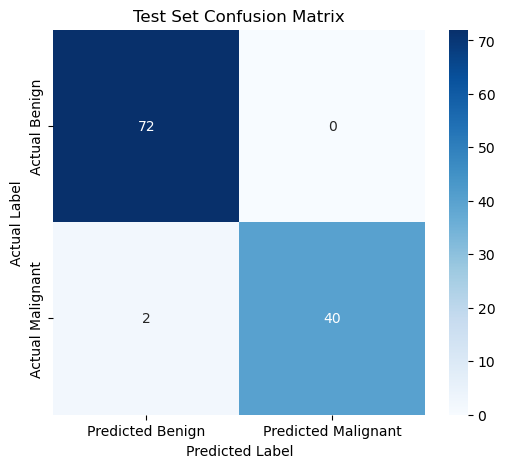

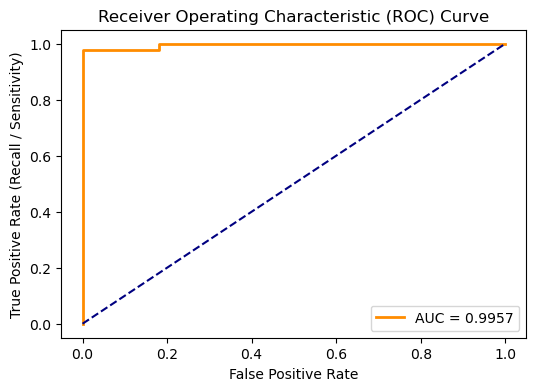

In [28]:
# 1. Retrieve the best model found by GridSearch
best_model = grid_result.best_estimator_

# 2. Make predictions on the unseen test set
# Scikeras KerasClassifier predict returns class labels directly (0 or 1)
y_pred = best_model.predict(X_test_scaled)
# Predict probabilities for the positive class (Malignant / 1) for ROC-AUC
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# 3. Generate Confusion Matrix & Classification Report
cm = confusion_matrix(y_test, y_pred)
cr = classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)'])

print("--- Classification Report ---")
print(cr)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

# 4. Visualize the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Benign', 'Predicted Malignant'],
            yticklabels=['Actual Benign', 'Actual Malignant'])
plt.title('Test Set Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 5. Plot the ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_pred_proba):.4f}", color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Breast Cancer Neural Network: Performance Report

This document explains the performance of our neural network on the unseen test data. The model achieved a **98% overall accuracy**, but in medical diagnoses, we look deeper than just accuracy to ensure patient safety. 

Here is a plain-English breakdown of the Classification Report metrics based on our results.

## Key Metrics Explained

* **Support (The Patient Count):** The actual number of cases in our test dataset. 
  * *In our test:* 72 Benign (healthy) cases and 42 Malignant (cancerous) cases, totaling 114 patients.
* **Precision (The "False Alarm" Check):** Out of all the tumors the model *predicted* as a specific class, how many were actually that class?
  * *For Malignant (1.00 or 100%):* When the model flagged a tumor as Malignant, it was correct 100% of the time. There were zero false alarms (False Positives), meaning no healthy patients were unnecessarily scared.
* **Recall / Sensitivity (The "Missed Cancer" Check):** Out of all the *actual* cases of a specific class in the real world, how many did the model successfully find?
  * *For Malignant (0.95 or 95%):* The model successfully identified 95% of all actual cancer cases. It missed roughly 5% (False Negatives). In medicine, maximizing Recall is the highest priority because missing a cancer diagnosis is the most dangerous error.
* **F1-Score:** The balance between Precision and Recall. It provides a single score to judge the model's overall reliability, which is especially useful if one class has more data than the other. 
  * *In our test:* Scores of 0.99 and 0.98 indicate an exceptionally well-balanced and robust model.
* **Accuracy:** The overall percentage of completely correct predictions across both benign and malignant classes.
  * *In our test:* The model was completely correct on 98% of the 114 test cases.
* **ROC-AUC Score:** This measures the model's underlying ability to separate the Malignant and Benign tumors. A score of 1.0 is perfect, and 0.5 is no better than flipping a coin.
  * *In our test:* A score of **0.9957** means the neural network's ability to distinguish between the two classes is virtually perfect.

## The Results in Plain English

Our neural network performed exceptionally well as a diagnostic assistant. 

If a medical professional were using this model today:
1. **Trust its warnings:** They can trust it completely when it flags a tumor as Malignant (100% Precision).
2. **Verify its all-clears:** The model caught 95% of the actual cancers (Recall). While very high, the remaining 5% represents a small number of missed cancer cases (False Negatives). This perfectly illustrates why AI is an *assistant*—doctors would still investigate suspicious cases even if the AI says they are benign.
3. **Overall Reliability:** It successfully and accurately diagnosed 98% of the 114 patients in the test trial.